# Short-Term Manufacturing Process Predictions

In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error
import lightgbm as lgb
from math import sqrt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset


# Importing Data and Setting up dataframe

In [2]:
df = pd.read_csv('/Users/preetshah/myenv/cnf/csci 82/final project/archive/continuous_factory_process.csv')
print(df.shape)

(14088, 116)


In [3]:
df.head()

,time_stamp,AmbientConditions.AmbientHumidity.U.Actual,AmbientConditions.AmbientTemperature.U.Actual,Machine1.RawMaterial.Property1,Machine1.RawMaterial.Property2,Machine1.RawMaterial.Property3,Machine1.RawMaterial.Property4,Machine1.RawMaterialFeederParameter.U.Actual,Machine1.Zone1Temperature.C.Actual,Machine1.Zone2Temperature.C.Actual,...,Stage2.Output.Measurement10.U.Actual,Stage2.Output.Measurement10.U.Setpoint,Stage2.Output.Measurement11.U.Actual,Stage2.Output.Measurement11.U.Setpoint,Stage2.Output.Measurement12.U.Actual,Stage2.Output.Measurement12.U.Setpoint,Stage2.Output.Measurement13.U.Actual,Stage2.Output.Measurement13.U.Setpoint,Stage2.Output.Measurement14.U.Actual,Stage2.Output.Measurement14.U.Setpoint
0,2019-03-06 10:52:33,17.24,23.53,11.54,200,963.0,247,1241.26,72.0,72.3,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71
1,2019-03-06 10:52:34,17.24,23.53,11.54,200,963.0,247,1246.09,72.0,72.3,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71
2,2019-03-06 10:52:35,17.24,23.53,11.54,200,963.0,247,1246.29,72.0,72.3,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71
3,2019-03-06 10:52:36,17.24,23.53,11.54,200,963.0,247,1247.59,72.0,72.3,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71
4,2019-03-06 10:52:37,17.24,23.53,11.54,200,963.0,247,1252.83,72.1,72.4,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71


### checking all the columns of the data and removing the second stage columns

In [4]:
for i in df.columns:
  print(i)

time_stamp
AmbientConditions.AmbientHumidity.U.Actual
AmbientConditions.AmbientTemperature.U.Actual
Machine1.RawMaterial.Property1
Machine1.RawMaterial.Property2
Machine1.RawMaterial.Property3
Machine1.RawMaterial.Property4
Machine1.RawMaterialFeederParameter.U.Actual
Machine1.Zone1Temperature.C.Actual
Machine1.Zone2Temperature.C.Actual
Machine1.MotorAmperage.U.Actual
Machine1.MotorRPM.C.Actual
Machine1.MaterialPressure.U.Actual
Machine1.MaterialTemperature.U.Actual
Machine1.ExitZoneTemperature.C.Actual
Machine2.RawMaterial.Property1
Machine2.RawMaterial.Property2
Machine2.RawMaterial.Property3
Machine2.RawMaterial.Property4
Machine2.RawMaterialFeederParameter.U.Actual
Machine2.Zone1Temperature.C.Actual
Machine2.Zone2Temperature.C.Actual
Machine2.MotorAmperage.U.Actual
Machine2.MotorRPM.C.Actual
Machine2.MaterialPressure.U.Actual
Machine2.MaterialTemperature.U.Actual
Machine2.ExitZoneTemperature.C.Actual
Machine3.RawMaterial.Property1
Machine3.RawMaterial.Property2
Machine3.RawMaterial

In [5]:
cols_stage2 = df.columns[72:116]   # dropping stage 2 columns
df = df.drop(cols_stage2, axis=1)
df.head()

,time_stamp,AmbientConditions.AmbientHumidity.U.Actual,AmbientConditions.AmbientTemperature.U.Actual,Machine1.RawMaterial.Property1,Machine1.RawMaterial.Property2,Machine1.RawMaterial.Property3,Machine1.RawMaterial.Property4,Machine1.RawMaterialFeederParameter.U.Actual,Machine1.Zone1Temperature.C.Actual,Machine1.Zone2Temperature.C.Actual,...,Stage1.Output.Measurement10.U.Actual,Stage1.Output.Measurement10.U.Setpoint,Stage1.Output.Measurement11.U.Actual,Stage1.Output.Measurement11.U.Setpoint,Stage1.Output.Measurement12.U.Actual,Stage1.Output.Measurement12.U.Setpoint,Stage1.Output.Measurement13.U.Actual,Stage1.Output.Measurement13.U.Setpoint,Stage1.Output.Measurement14.U.Actual,Stage1.Output.Measurement14.U.Setpoint
0,2019-03-06 10:52:33,17.24,23.53,11.54,200,963.0,247,1241.26,72.0,72.3,...,8.06,8.65,5.54,6.16,1.66,2.02,2.69,3.16,14.51,17.72
1,2019-03-06 10:52:34,17.24,23.53,11.54,200,963.0,247,1246.09,72.0,72.3,...,7.55,8.65,5.13,6.16,1.04,2.02,2.70,3.16,0.00,17.72
2,2019-03-06 10:52:35,17.24,23.53,11.54,200,963.0,247,1246.29,72.0,72.3,...,7.55,8.65,5.13,6.16,1.04,2.02,2.70,3.16,0.00,17.72
3,2019-03-06 10:52:36,17.24,23.53,11.54,200,963.0,247,1247.59,72.0,72.3,...,7.55,8.65,5.13,6.16,1.04,2.02,2.70,3.16,0.00,17.72
4,2019-03-06 10:52:37,17.24,23.53,11.54,200,963.0,247,1252.83,72.1,72.4,...,7.54,8.65,5.15,6.16,1.15,2.02,2.72,3.16,0.00,17.72


In [6]:
primary_actual_cols = []
primary_setpoint_cols = []
cols = list(df.columns)
for i in cols:

  if 'Output' in i:
    print(i)
    primary_actual_cols.append(i)
      
for i in primary_actual_cols:
    if 'Setpoint' in i:
        primary_setpoint_cols.append(i)
        primary_actual_cols.remove(i)
y, X  = df[primary_actual_cols], df.drop(primary_actual_cols, axis=1)



Stage1.Output.Measurement0.U.Actual
Stage1.Output.Measurement0.U.Setpoint
Stage1.Output.Measurement1.U.Actual
Stage1.Output.Measurement1.U.Setpoint
Stage1.Output.Measurement2.U.Actual
Stage1.Output.Measurement2.U.Setpoint
Stage1.Output.Measurement3.U.Actual
Stage1.Output.Measurement3.U.Setpoint
Stage1.Output.Measurement4.U.Actual
Stage1.Output.Measurement4.U.Setpoint
Stage1.Output.Measurement5.U.Actual
Stage1.Output.Measurement5.U.Setpoint
Stage1.Output.Measurement6.U.Actual
Stage1.Output.Measurement6.U.Setpoint
Stage1.Output.Measurement7.U.Actual
Stage1.Output.Measurement7.U.Setpoint
Stage1.Output.Measurement8.U.Actual
Stage1.Output.Measurement8.U.Setpoint
Stage1.Output.Measurement9.U.Actual
Stage1.Output.Measurement9.U.Setpoint
Stage1.Output.Measurement10.U.Actual
Stage1.Output.Measurement10.U.Setpoint
Stage1.Output.Measurement11.U.Actual
Stage1.Output.Measurement11.U.Setpoint
Stage1.Output.Measurement12.U.Actual
Stage1.Output.Measurement12.U.Setpoint
Stage1.Output.Measurement13.U.Ac

In [7]:
print(primary_actual_cols)

['Stage1.Output.Measurement0.U.Actual', 'Stage1.Output.Measurement1.U.Actual', 'Stage1.Output.Measurement2.U.Actual', 'Stage1.Output.Measurement3.U.Actual', 'Stage1.Output.Measurement4.U.Actual', 'Stage1.Output.Measurement5.U.Actual', 'Stage1.Output.Measurement6.U.Actual', 'Stage1.Output.Measurement7.U.Actual', 'Stage1.Output.Measurement8.U.Actual', 'Stage1.Output.Measurement9.U.Actual', 'Stage1.Output.Measurement10.U.Actual', 'Stage1.Output.Measurement11.U.Actual', 'Stage1.Output.Measurement12.U.Actual', 'Stage1.Output.Measurement13.U.Actual', 'Stage1.Output.Measurement14.U.Actual']


In [8]:
print(X.shape)
print(y.shape)

(14088, 57)
(14088, 15)


In [9]:

X = X.drop(['time_stamp'], axis=1)


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, shuffle=False
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, shuffle=False
)


scaler_x = StandardScaler()
scaler_y = StandardScaler()

scaler_x.fit(X_train)
scaler_y.fit(y_train)

X_train_scaled = scaler_x.transform(X_train)
X_val_scaled   = scaler_x.transform(X_val)
X_test_scaled  = scaler_x.transform(X_test)

y_train_scaled = scaler_y.transform(y_train)
y_val_scaled   = scaler_y.transform(y_val)
y_test_scaled  = scaler_y.transform(y_test)


pca = PCA(n_components=30)
pca.fit(X_train_scaled)

X_train_pca = pca.transform(X_train_scaled)
X_val_pca   = pca.transform(X_val_scaled)
X_test_pca  = pca.transform(X_test_scaled)


print("Train PCA shape:", X_train_pca.shape)
print("Val PCA shape:", X_val_pca.shape)
print("Test PCA shape:", X_test_pca.shape)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative explained variance:", np.sum(pca.explained_variance_ratio_))


Train PCA shape: (9861, 30)
Val PCA shape: (2113, 30)
Test PCA shape: (2114, 30)
Explained variance ratio: [0.26949125 0.21521516 0.11028919 0.05932331 0.04938178 0.02404403
 0.02234234 0.01999293 0.01920114 0.01811272 0.01770982 0.01758089
 0.01729455 0.01726304 0.01602456 0.01483985 0.01381376 0.01207875
 0.01157428 0.01036265 0.00750059 0.00648671 0.00578377 0.00495655
 0.00404913 0.00372146 0.0030296  0.00260202 0.00178125 0.00142092]
Cumulative explained variance: 0.9972680058805037


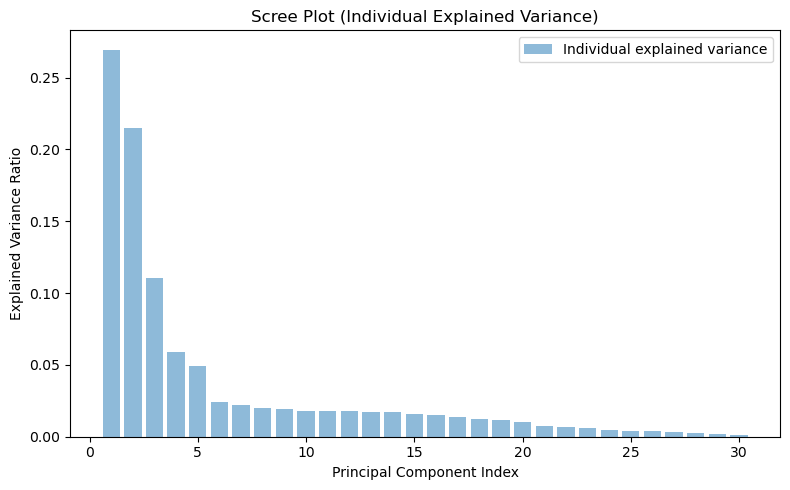

In [10]:
explained_variance_ratio = pca.explained_variance_ratio_
plt.figure(figsize=(8, 5))

plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, alpha=0.5, align='center', label='Individual explained variance')
plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Component Index')
plt.legend(loc='best')
plt.title('Scree Plot (Individual Explained Variance)')
plt.tight_layout()
plt.show()

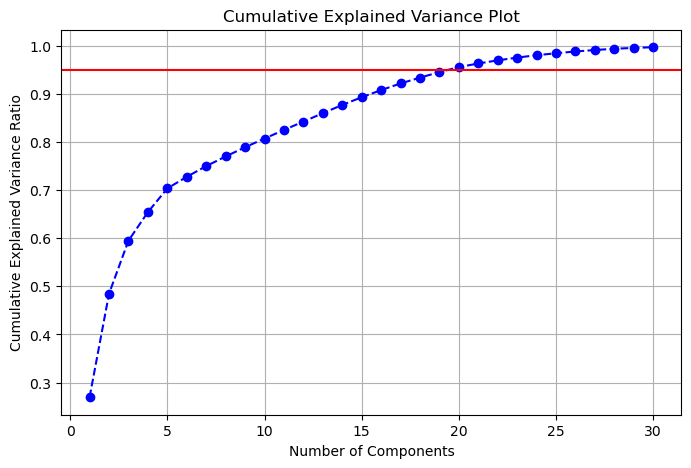

In [11]:
cumulative_variance = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title('Cumulative Explained Variance Plot')
plt.axhline(y=0.95, color='r', linestyle='-') 
plt.grid(True)
plt.show()

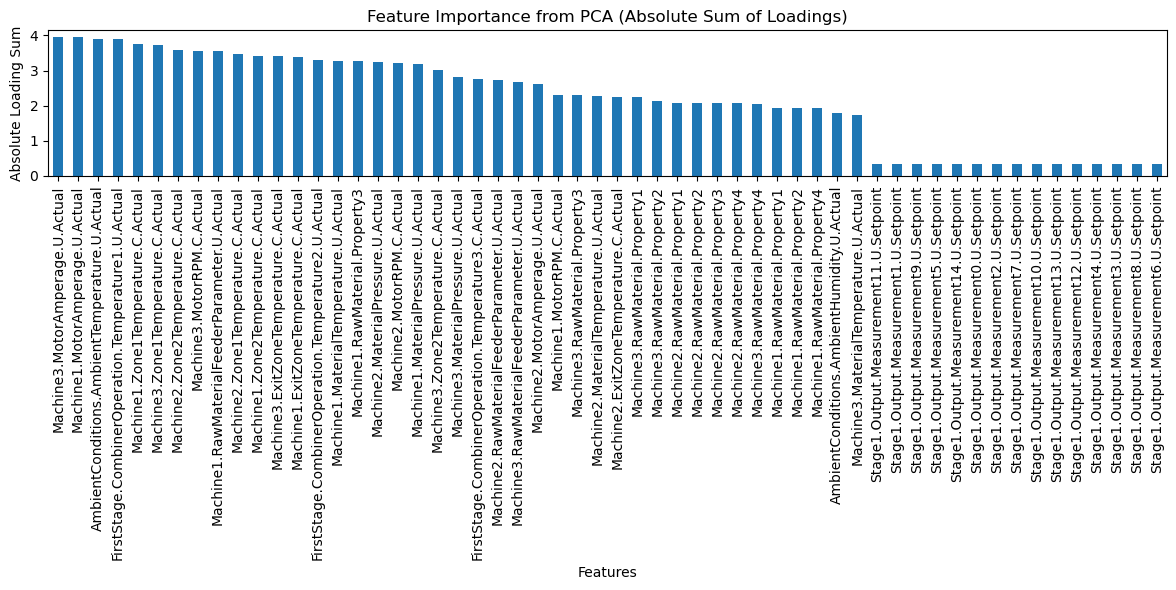

In [12]:
loadings = pca.components_

feature = X.columns

loadings_df = pd.DataFrame(
    loadings.T,
    columns=[f'PC{i+1}' for i in range(loadings.shape[0])],
    index=feature
)

feature_importance = loadings_df.abs().sum(axis=1).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
feature_importance.plot(kind='bar')
plt.title('Feature Importance from PCA (Absolute Sum of Loadings)')
plt.xlabel('Features')
plt.ylabel('Absolute Loading Sum')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Dropping the setpoint columns as it seems they are not contributing much to the PCA and as explained in the data description they are only used to set baseline expectation of machince output.

In [13]:
print(primary_setpoint_cols)

['Stage1.Output.Measurement0.U.Setpoint', 'Stage1.Output.Measurement1.U.Setpoint', 'Stage1.Output.Measurement2.U.Setpoint', 'Stage1.Output.Measurement3.U.Setpoint', 'Stage1.Output.Measurement4.U.Setpoint', 'Stage1.Output.Measurement5.U.Setpoint', 'Stage1.Output.Measurement6.U.Setpoint', 'Stage1.Output.Measurement7.U.Setpoint', 'Stage1.Output.Measurement8.U.Setpoint', 'Stage1.Output.Measurement9.U.Setpoint', 'Stage1.Output.Measurement10.U.Setpoint', 'Stage1.Output.Measurement11.U.Setpoint', 'Stage1.Output.Measurement12.U.Setpoint', 'Stage1.Output.Measurement13.U.Setpoint', 'Stage1.Output.Measurement14.U.Setpoint']


In [14]:
X = X.drop(primary_setpoint_cols, axis=1)

In [15]:
print(X.shape)
print(y.shape)

(14088, 41)
(14088, 15)


### Re-running PCA for better Accuracy, dropped all the setpoint columns as they seem not have much of contribution. Split the data into train, test, and validation datasets. The split is train 70%, test 15% and validation is 15%. 

In [16]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, shuffle=False
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, shuffle=False
)


scaler_x = StandardScaler()
scaler_y = StandardScaler()

scaler_x.fit(X_train)
scaler_y.fit(y_train)

X_train_scaled = scaler_x.transform(X_train)
X_val_scaled   = scaler_x.transform(X_val)
X_test_scaled  = scaler_x.transform(X_test)

y_train_scaled = scaler_y.transform(y_train)
y_val_scaled   = scaler_y.transform(y_val)
y_test_scaled  = scaler_y.transform(y_test)


pca = PCA(n_components=30)
pca.fit(X_train_scaled)

X_train_pca = pca.transform(X_train_scaled)
X_val_pca   = pca.transform(X_val_scaled)
X_test_pca  = pca.transform(X_test_scaled)


print("X Train PCA shape:", X_train_pca.shape)
print("X Val PCA shape:", X_val_pca.shape)
print("X Test PCA shape:", X_test_pca.shape)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative explained variance:", np.sum(pca.explained_variance_ratio_))


X Train PCA shape: (9861, 30)
X Val PCA shape: (2113, 30)
X Test PCA shape: (2114, 30)
Explained variance ratio: [0.29453679 0.15118291 0.08106637 0.06773721 0.0328434  0.03059458
 0.02742715 0.02626337 0.02485862 0.02425048 0.02410045 0.02374498
 0.02361295 0.02188733 0.02027113 0.01888177 0.01652746 0.01582278
 0.01417336 0.01024826 0.00886214 0.00790811 0.0067802  0.00553063
 0.00508297 0.00413993 0.00355455 0.00243315 0.00194114 0.00138367]
Cumulative explained variance: 0.9976478572540072


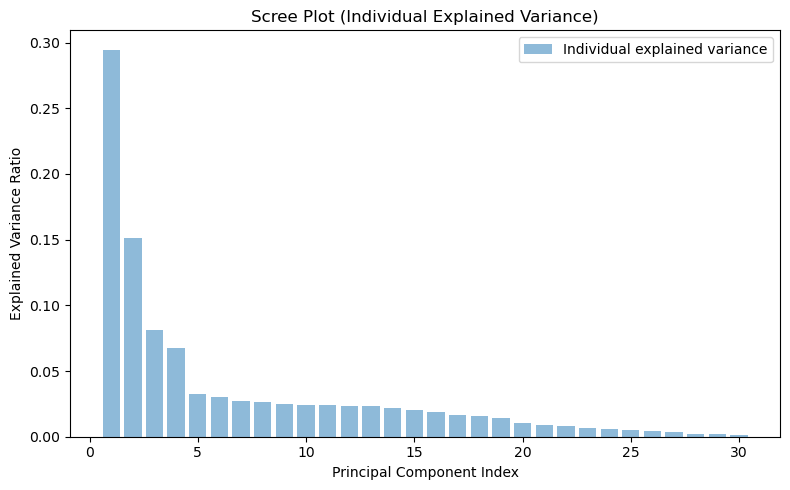

In [17]:
import matplotlib.pyplot as plt
explained_variance_ratio = pca.explained_variance_ratio_
plt.figure(figsize=(8, 5))

plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, alpha=0.5, align='center', label='Individual explained variance')
plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Component Index')
plt.legend(loc='best')
plt.title('Scree Plot (Individual Explained Variance)')
plt.tight_layout()
plt.show()

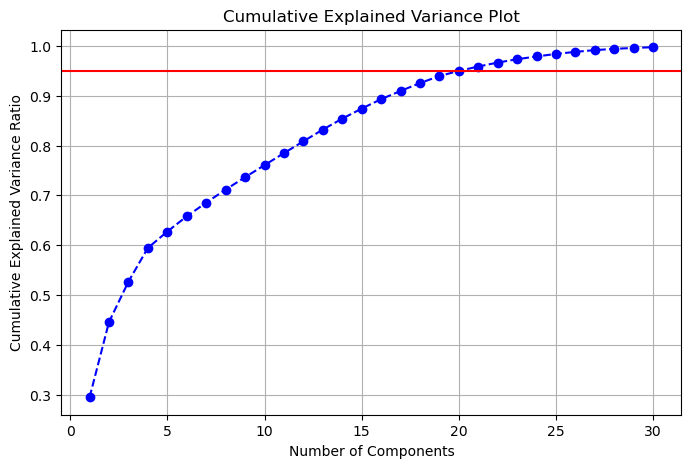

In [18]:
cumulative_variance = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title('Cumulative Explained Variance Plot')
plt.axhline(y=0.95, color='r', linestyle='-') 
plt.grid(True)
plt.show()

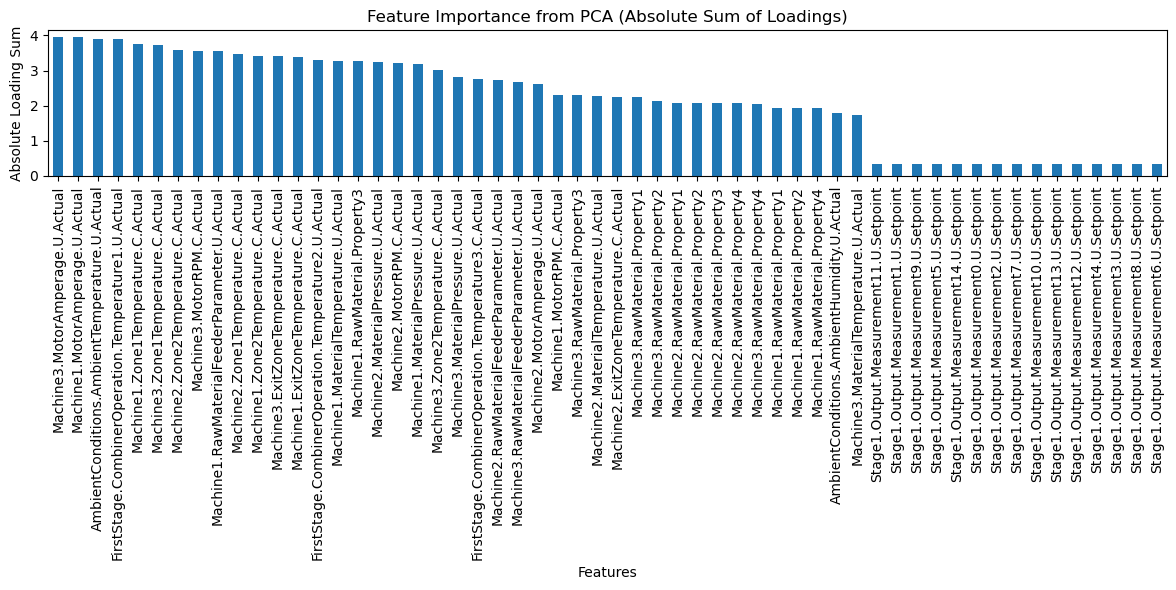

In [19]:

loadings = pca.components_
feature = X.columns
loadings_df1 = pd.DataFrame(
    loadings.T,
    columns=[f'PC{i+1}' for i in range(loadings.shape[0])],
    index=feature
)

feature_importance = loadings_df.abs().sum(axis=1).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
feature_importance.plot(kind='bar')
plt.title('Feature Importance from PCA (Absolute Sum of Loadings)')
plt.xlabel('Features')
plt.ylabel('Absolute Loading Sum')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# PCA look better, The first PCA seems to be explain the variance better. The first pca explains a little more of the variance than the previous PCA. The map below shows which features contributed to diffrent PCA's. It also helps understand which feature is important which seems to 

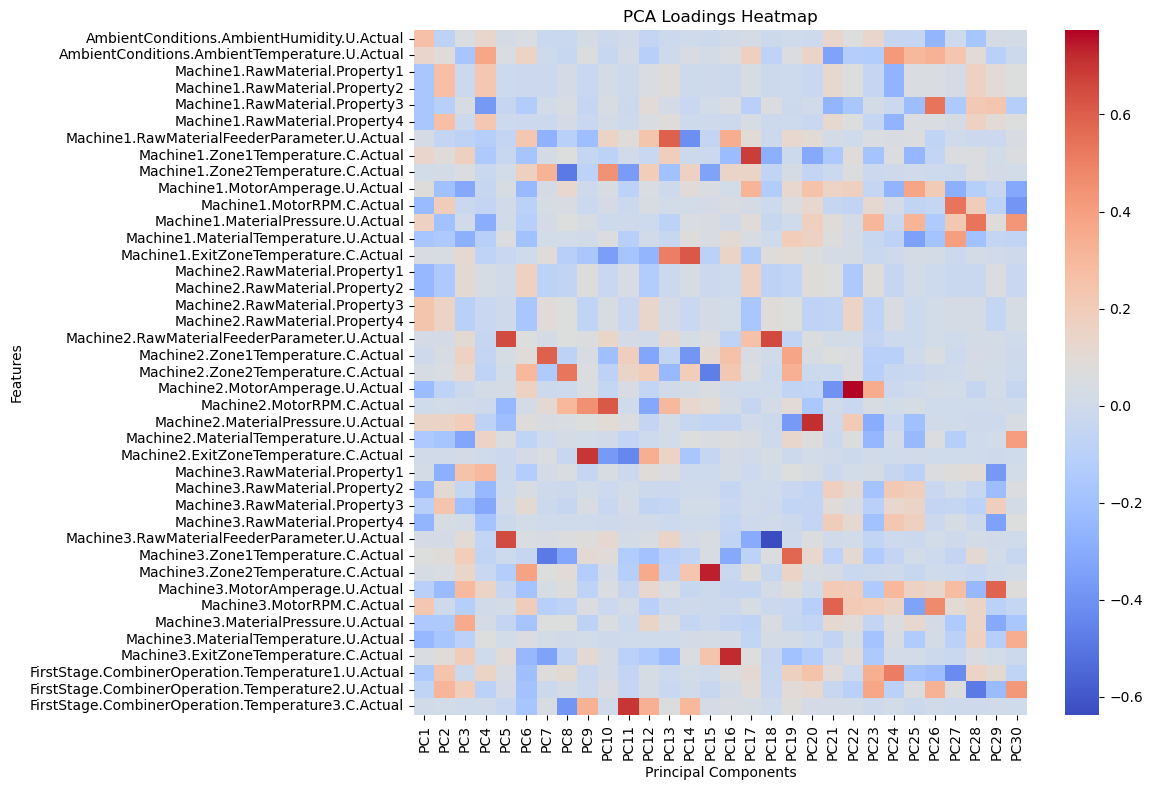

In [20]:
plt.figure(figsize=(12,8))
sns.heatmap(loadings_df1, cmap="coolwarm", annot=False)
plt.title("PCA Loadings Heatmap")
plt.xlabel("Principal Components")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# Model Traning
## LightLGB + PCA 
## LSTM + PCA 
## PCA + LSTM + CONV 
## PCA + ensemble(LIGHTLGB + LMSTCONV)
## ensemble(LIGHTLGB + LMSTCONV)

In [21]:
print(primary_actual_cols)

['Stage1.Output.Measurement0.U.Actual', 'Stage1.Output.Measurement1.U.Actual', 'Stage1.Output.Measurement2.U.Actual', 'Stage1.Output.Measurement3.U.Actual', 'Stage1.Output.Measurement4.U.Actual', 'Stage1.Output.Measurement5.U.Actual', 'Stage1.Output.Measurement6.U.Actual', 'Stage1.Output.Measurement7.U.Actual', 'Stage1.Output.Measurement8.U.Actual', 'Stage1.Output.Measurement9.U.Actual', 'Stage1.Output.Measurement10.U.Actual', 'Stage1.Output.Measurement11.U.Actual', 'Stage1.Output.Measurement12.U.Actual', 'Stage1.Output.Measurement13.U.Actual', 'Stage1.Output.Measurement14.U.Actual']


# Started with the lightGBM model for time series predictions. The model are looking to predict 12, 20, 30 60 sec of immediate future.

In [22]:
def create_sparse_lags(df, cols, lags):
    """
    Create lag features for each column in cols using lags (list of ints).
    Returns new dataframe with lag columns appended. Caller should dropna later.
    """
    df2 = df.copy()
    for c in cols:
        for lag in lags:
            df2[f"{c}_lag{lag}"] = df2[c].shift(lag)
    return df2

lag_list = [12,20,30,60]

df_work = create_sparse_lags(X_train, X_train.columns, lag_list)

max_lag = max(lag_list)
df_work = df_work.dropna().reset_index(drop=True)
print("After lagging, rows:", len(df_work))

horizons = [12, 20, 30, 60]  
y_h = {}

for h in horizons:
    y_df = y[primary_actual_cols].shift(-h).iloc[:-h].reset_index(drop=True)
    y_h[h] = y_df


max_horizon = max(horizons)
X_full = df_work.iloc[:-max_horizon].reset_index(drop=True)

X_full = X_full.drop(columns=[c for c in primary_actual_cols if c in X_full.columns], errors='ignore')
print("X_full shape:", X_full.shape)

n = len(X_full)
train_end = int(0.7 * n)  
val_end   = int(0.85 * n)  

X_train1 = X_full.iloc[:train_end].copy()
X_val1   = X_full.iloc[train_end:val_end].copy()
X_test1  = X_full.iloc[val_end:].copy()

After lagging, rows: 9801
X_full shape: (9741, 205)


/var/folders/44/bj7j3j2s1wn225x04psby4lm0000gn/T/ipykernel_66877/1493335227.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df2[f"{c}_lag{lag}"] = df2[c].shift(lag)
/var/folders/44/bj7j3j2s1wn225x04psby4lm0000gn/T/ipykernel_66877/1493335227.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df2[f"{c}_lag{lag}"] = df2[c].shift(lag)
/var/folders/44/bj7j3j2s1wn225x04psby4lm0000gn/T/ipykernel_66877/1493335227.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many tim

# created lags above for model training of 12,20,30,60 helping the model understand pattern in time frames.

In [23]:

results = {}

for h in horizons:
    print("\n Processing horizon:", h)

    y_all = y_h[h].iloc[:len(X_full)].reset_index(drop=True)
    y_train1 = y_all.iloc[:train_end].reset_index(drop=True)
    y_val1   = y_all.iloc[train_end:val_end].reset_index(drop=True)
    y_test1  = y_all.iloc[val_end:].reset_index(drop=True)


    base = lgb.LGBMRegressor(
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.9,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )
    model = MultiOutputRegressor(base, n_jobs=-1)
    model.fit(X_train1, y_train1)

    y_val_pred = model.predict(X_val1)
    y_test_pred = model.predict(X_test1)

    
    per_target_rmse_val = {}
    per_target_rmse_test = {}
    for i, col in enumerate(primary_actual_cols):
        per_target_rmse_val[col] = sqrt(mean_squared_error(y_val1.iloc[:, i], y_val_pred[:, i]))
        per_target_rmse_test[col] = sqrt(mean_squared_error(y_test1.iloc[:, i], y_test_pred[:, i]))

    overall_rmse_val = sqrt(mean_squared_error(y_val1.values.flatten(), y_val_pred.flatten()))
    overall_rmse_test = sqrt(mean_squared_error(y_test1.values.flatten(), y_test_pred.flatten()))

    print(f"Horizon {h}: Validation RMSE: {overall_rmse_val:.4f}, Test RMSE: {overall_rmse_test:.4f}")

    results[h] = {
        "model": model,
        "y_val": y_val1,
        "y_val_pred": y_val_pred,
        "y_test": y_test1,
        "y_test_pred": y_test_pred,
        "per_target_rmse_val": per_target_rmse_val,
        "per_target_rmse_test": per_target_rmse_test,
        "overall_rmse_val": overall_rmse_val,
        "overall_rmse_test": overall_rmse_test
    }
    



 Processing horizon: 12
Horizon 12: Validation RMSE: 2.8491, Test RMSE: 3.1406

 Processing horizon: 20
Horizon 20: Validation RMSE: 2.8070, Test RMSE: 3.6150

 Processing horizon: 30
Horizon 30: Validation RMSE: 3.1895, Test RMSE: 3.4410

 Processing horizon: 60
Horizon 60: Validation RMSE: 3.2071, Test RMSE: 3.9087


# The model has decent outcome for all the horizons, Testing further with LSTM model for lower RMSE.


Training LSTM for horizon 12
Epoch 10/50 Train Loss: 0.265533, Val Loss: 2.395172
Epoch 20/50 Train Loss: 0.231133, Val Loss: 1.554098
Epoch 30/50 Train Loss: 0.204468, Val Loss: 2.538803
Epoch 40/50 Train Loss: 0.151855, Val Loss: 1.502345
Epoch 50/50 Train Loss: 0.106646, Val Loss: 1.467084
Horizon 12  Val RMSE: 4.2845, Test RMSE: 4.2519

Training LSTM for horizon 20
Epoch 10/50 Train Loss: 0.261332, Val Loss: 2.093455
Epoch 20/50 Train Loss: 0.223392, Val Loss: 2.707217
Epoch 30/50 Train Loss: 0.198970, Val Loss: 1.784407
Epoch 40/50 Train Loss: 0.168421, Val Loss: 1.395860
Epoch 50/50 Train Loss: 0.124022, Val Loss: 2.368084
Horizon 20  Val RMSE: 5.3710, Test RMSE: 5.1669

Training LSTM for horizon 30
Epoch 10/50 Train Loss: 0.253241, Val Loss: 10.017851
Epoch 20/50 Train Loss: 0.224654, Val Loss: 6.591621
Epoch 30/50 Train Loss: 0.211048, Val Loss: 10.206573
Epoch 40/50 Train Loss: 0.188480, Val Loss: 4.676694
Epoch 50/50 Train Loss: 0.154995, Val Loss: 3.811606
Horizon 30  Val R

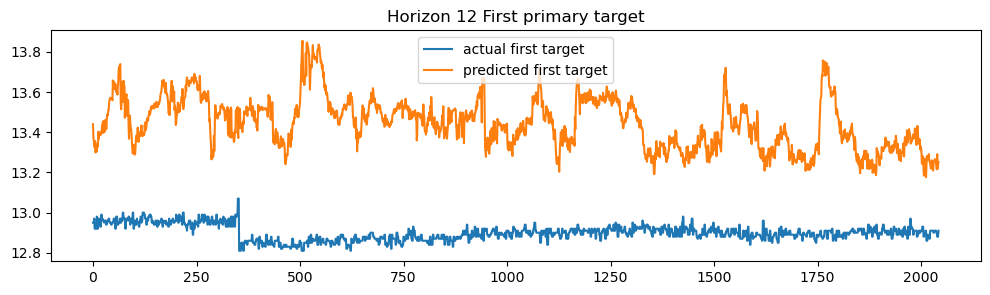

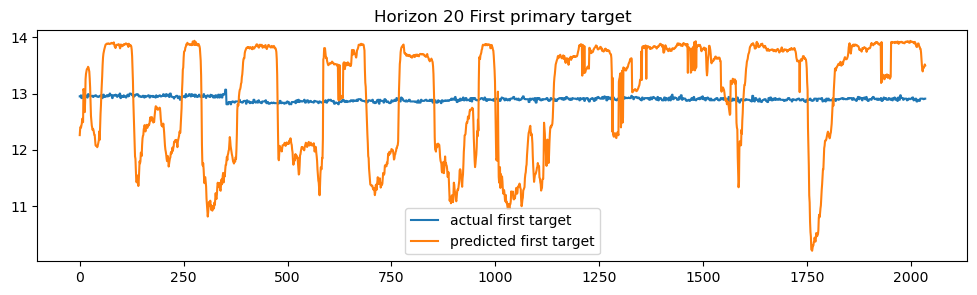

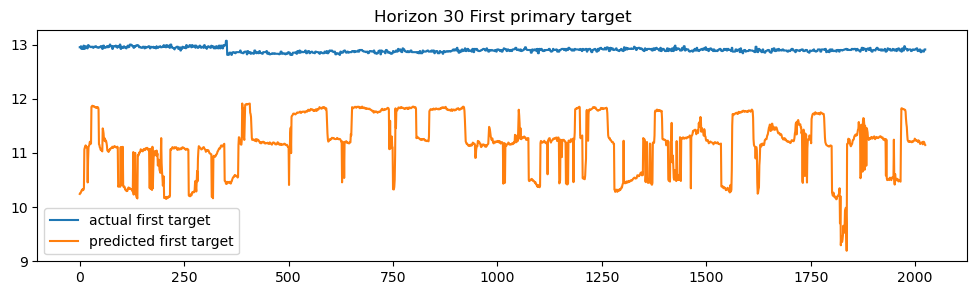

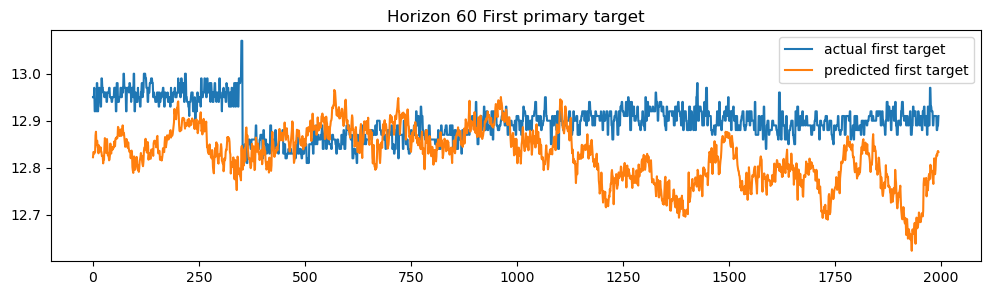

In [25]:

feature_cols = X.columns.tolist()
target_cols  = y.columns.tolist()


class TimeSeriesDataset(Dataset):
    def __init__(self, X, y, seq_len, horizon):
        self.X = X
        self.y = y
        self.seq_len = seq_len
        self.horizon = horizon
        self.n_samples = X.shape[0] - seq_len - horizon + 1

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        X_seq = self.X[idx: idx+self.seq_len]
        y_seq = self.y[idx+self.seq_len + self.horizon - 1]
        return torch.FloatTensor(X_seq), torch.FloatTensor(y_seq)

seq_len = 60
batch_size = 64
hidden_size = 128
num_layers = 2
learning_rate = 0.001
num_epochs = 50
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
horizons = [12, 20, 30, 60]



X_train = X_train_pca #.values
X_val   = X_val_pca #.values
X_test  = X_test_pca #.values

#y_train = y_train.values
#y_val   = y_val.values
#y_test  = y_test.values

y_train = y_train_scaled
y_val = y_val_scaled 
y_test = y_test_scaled

datasets = {}
loaders = {}
for h in horizons:
    train_dataset = TimeSeriesDataset(X_train, y_train, seq_len, horizon=h)
    val_dataset   = TimeSeriesDataset(X_val, y_val, seq_len, horizon=h)
    test_dataset  = TimeSeriesDataset(X_test, y_test, seq_len, horizon=h)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


    datasets[h] = (train_dataset, val_dataset, test_dataset)
    loaders[h] = (train_loader, val_loader, test_loader)

# Model
class LSTMForecast(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super(LSTMForecast, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out


results = {}
input_size = X_train.shape[1]
output_size = y_train.shape[1]

for h in horizons:
    print(f"\nTraining LSTM for horizon {h}")
    model = LSTMForecast(input_size, hidden_size, num_layers, output_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.MSELoss()

    train_loader, val_loader, test_loader = loaders[h]

  
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * X_batch.size(0)
        epoch_loss /= len(train_loader.dataset)

        
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                y_pred = model(X_batch)
                val_loss += criterion(y_pred, y_batch).item() * X_batch.size(0)
        val_loss /= len(val_loader.dataset)

        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs} Train Loss: {epoch_loss:.6f}, Val Loss: {val_loss:.6f}")

    model.eval()

 
    y_val_pred_list = []
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_hat = model(X_batch)
            y_val_pred_list.append(y_hat.cpu().numpy())
    y_val_pred = np.vstack(y_val_pred_list)
    y_val_pred_rescaled = scaler_y.inverse_transform(y_val_pred)
    y_val_rescaled = scaler_y.inverse_transform(y_val[:len(y_val_pred)])

    per_target_rmse_val = [sqrt(mean_squared_error(y_val_rescaled[:,i], y_val_pred_rescaled[:,i]))
                           for i in range(output_size)]
    overall_rmse_val = sqrt(mean_squared_error(y_val_rescaled.flatten(), y_val_pred_rescaled.flatten()))

  
    y_test_pred_list = []
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            y_hat = model(X_batch)
            y_test_pred_list.append(y_hat.cpu().numpy())
    y_test_pred = np.vstack(y_test_pred_list)
    y_test_pred_rescaled = scaler_y.inverse_transform(y_test_pred)
    y_test_rescaled = scaler_y.inverse_transform(y_test[:len(y_test_pred)])

    per_target_rmse_test = [sqrt(mean_squared_error(y_test_rescaled[:,i], y_test_pred_rescaled[:,i]))
                            for i in range(output_size)]
    overall_rmse_test = sqrt(mean_squared_error(y_test_rescaled.flatten(), y_test_pred_rescaled.flatten()))

    print(f"Horizon {h}  Val RMSE: {overall_rmse_val:.4f}, Test RMSE: {overall_rmse_test:.4f}")


    results[h] = {
        "model": model,
        "y_val": y_val_rescaled,
        "y_val_pred": y_val_pred_rescaled,
        "y_test": y_test_rescaled,
        "y_test_pred": y_test_pred_rescaled,
        "per_target_rmse_val": per_target_rmse_val,
        "per_target_rmse_test": per_target_rmse_test,
        "overall_rmse_val": overall_rmse_val,
        "overall_rmse_test": overall_rmse_test
    }


for h in horizons:
    plt.figure(figsize=(12,3))
    plt.plot(results[h]["y_test"][:,0], label="actual first target")
    plt.plot(results[h]["y_test_pred"][:,0], label="predicted first target")
    plt.title(f"Horizon {h} First primary target")
    plt.legend()
    plt.show()


# The LSTM model is not doing better than the LightGBM model, the RSME is higher. The prediction graph look okay but it is off ony horizon 12 and 30.


 Training LSTM for horizon 12
Epoch 10/50 Train Loss: 0.263680, Val Loss: 4.771667
Epoch 20/50 Train Loss: 0.218603, Val Loss: 4.131642
Epoch 30/50 Train Loss: 0.194233, Val Loss: 2.965835
Epoch 40/50 Train Loss: 0.148372, Val Loss: 2.275370
Epoch 50/50 Train Loss: 0.095480, Val Loss: 2.097232
Horizon 12 Val RMSE: 4.6259, Test RMSE: 3.2861

 Training LSTM for horizon 20
Epoch 10/50 Train Loss: 0.253666, Val Loss: 2.809750
Epoch 20/50 Train Loss: 0.232993, Val Loss: 1.134140
Epoch 30/50 Train Loss: 0.193017, Val Loss: 0.992632
Epoch 40/50 Train Loss: 0.176223, Val Loss: 1.105195
Epoch 50/50 Train Loss: 0.135474, Val Loss: 1.348291
Horizon 20 Val RMSE: 3.4721, Test RMSE: 4.1989

 Training LSTM for horizon 30
Epoch 10/50 Train Loss: 0.243826, Val Loss: 4.085350
Epoch 20/50 Train Loss: 0.210794, Val Loss: 3.819865
Epoch 30/50 Train Loss: 0.172713, Val Loss: 4.083854
Epoch 40/50 Train Loss: 0.119662, Val Loss: 2.824482
Epoch 50/50 Train Loss: 0.075579, Val Loss: 2.762875
Horizon 30 Val RMS

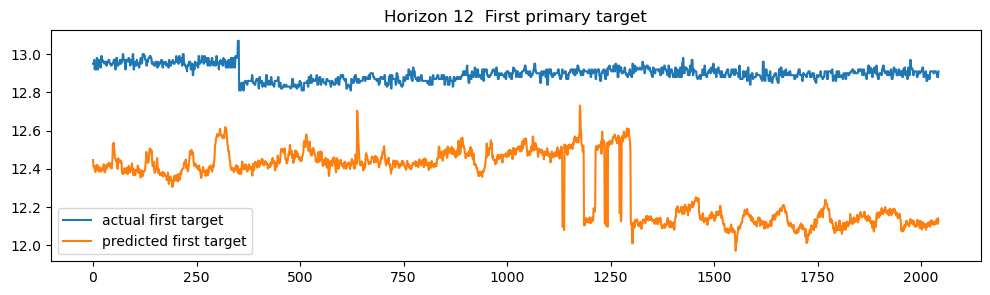

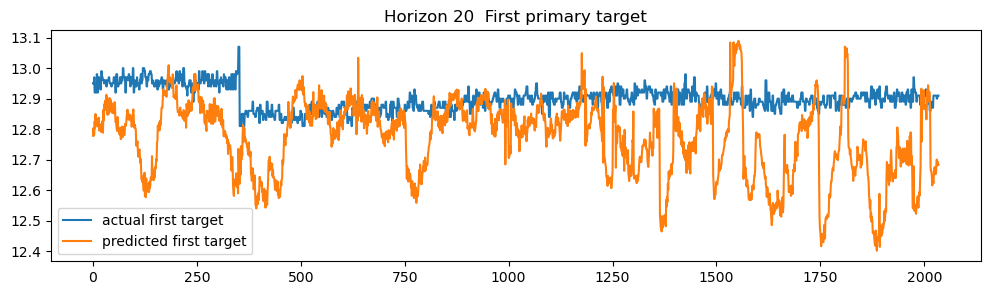

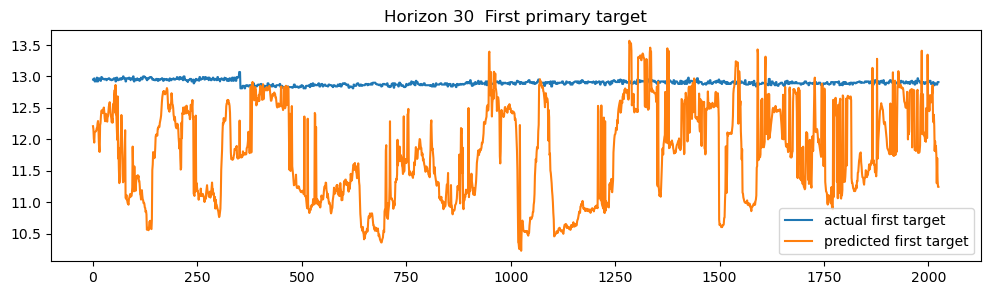

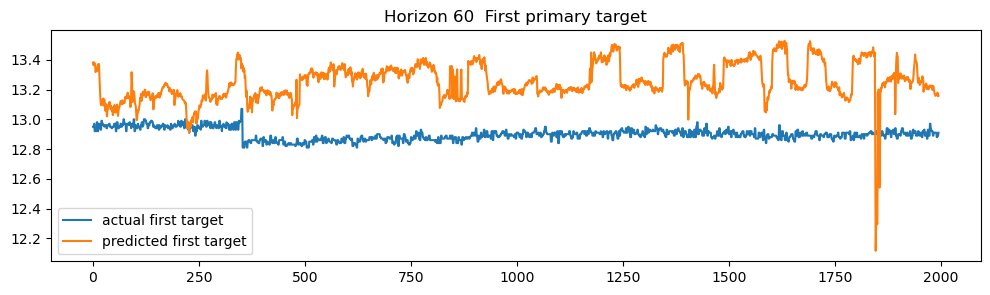

In [28]:
seq_len = 60
batch_size = 64
hidden_size = 128
num_layers = 2
learning_rate = 0.001
num_epochs = 50
if torch.backends.mps.is_available():
    device = torch.device("mps")
horizons = [12, 20, 30, 60]



# LSTM + Conv1D Model

class LSTMConv(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size, conv_channels=32, kernel_size=3):
        super(LSTMConv, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_size, out_channels=conv_channels, kernel_size=kernel_size, padding=kernel_size//2)
        self.relu = nn.ReLU()
        self.lstm = nn.LSTM(conv_channels, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
       
        x = x.permute(0,2,1)         
        x = self.conv1(x)
        x = self.relu(x)
        x = x.permute(0,2,1)         
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out

results = {}
input_size = X_train.shape[1]
output_size = y_train.shape[1]

for h in horizons:
    print(f"\n Training LSTM for horizon {h}")
    model = LSTMForecast(input_size, hidden_size, num_layers, output_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.MSELoss()

    train_loader, val_loader, test_loader = loaders[h]


    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * X_batch.size(0)
        epoch_loss /= len(train_loader.dataset)

     
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                y_pred = model(X_batch)
                val_loss += criterion(y_pred, y_batch).item() * X_batch.size(0)
        val_loss /= len(val_loader.dataset)

        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs} Train Loss: {epoch_loss:.6f}, Val Loss: {val_loss:.6f}")

    model.eval()


    y_val_pred_list = []
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_hat = model(X_batch)
            y_val_pred_list.append(y_hat.cpu().numpy())
    y_val_pred = np.vstack(y_val_pred_list)
    y_val_pred_rescaled = scaler_y.inverse_transform(y_val_pred)
    y_val_rescaled = scaler_y.inverse_transform(y_val[:len(y_val_pred)])

    per_target_rmse_val = [sqrt(mean_squared_error(y_val_rescaled[:,i], y_val_pred_rescaled[:,i]))
                           for i in range(output_size)]
    overall_rmse_val = sqrt(mean_squared_error(y_val_rescaled.flatten(), y_val_pred_rescaled.flatten()))

    y_test_pred_list = []
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            y_hat = model(X_batch)
            y_test_pred_list.append(y_hat.cpu().numpy())
    y_test_pred = np.vstack(y_test_pred_list)
    y_test_pred_rescaled = scaler_y.inverse_transform(y_test_pred)
    y_test_rescaled = scaler_y.inverse_transform(y_test[:len(y_test_pred)])

    per_target_rmse_test = [sqrt(mean_squared_error(y_test_rescaled[:,i], y_test_pred_rescaled[:,i]))
                            for i in range(output_size)]
    overall_rmse_test = sqrt(mean_squared_error(y_test_rescaled.flatten(), y_test_pred_rescaled.flatten()))

    print(f"Horizon {h} Val RMSE: {overall_rmse_val:.4f}, Test RMSE: {overall_rmse_test:.4f}")


    results[h] = {
        "model": model,
        "y_val": y_val_rescaled,
        "y_val_pred": y_val_pred_rescaled,
        "y_test": y_test_rescaled,
        "y_test_pred": y_test_pred_rescaled,
        "per_target_rmse_val": per_target_rmse_val,
        "per_target_rmse_test": per_target_rmse_test,
        "overall_rmse_val": overall_rmse_val,
        "overall_rmse_test": overall_rmse_test
    }
    


for h in horizons:
    plt.figure(figsize=(12,3))
    plt.plot(results[h]["y_test"][:,0], label="actual first target")
    plt.plot(results[h]["y_test_pred"][:,0], label="predicted first target")
    plt.title(f"Horizon {h}  First primary target")
    plt.legend()
    plt.show()

# Updated the model with convolutional layer to help the model. RMSE did not exactly get better and graph looks a little off.


 Training LSTMConv for horizon 12
Epoch 10/50 Train Loss=0.300675 Val RMSE=3.9537
Early stopping at epoch 13


/var/folders/44/bj7j3j2s1wn225x04psby4lm0000gn/T/ipykernel_60509/2617597184.py:114: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(f"best_lst

Horizon 12  Test RMSE: 4.5276

 Training LSTMConv for horizon 20
Epoch 10/50 Train Loss=0.309294 Val RMSE=4.1231
Epoch 20/50 Train Loss=0.264768 Val RMSE=3.5983
Early stopping at epoch 24
Horizon 20  Test RMSE: 5.0191

 Training LSTMConv for horizon 30


/var/folders/44/bj7j3j2s1wn225x04psby4lm0000gn/T/ipykernel_60509/2617597184.py:114: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(f"best_lst

Epoch 10/50 Train Loss=0.351463 Val RMSE=4.0325
Early stopping at epoch 13


/var/folders/44/bj7j3j2s1wn225x04psby4lm0000gn/T/ipykernel_60509/2617597184.py:114: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(f"best_lst

Horizon 30  Test RMSE: 5.1534

 Training LSTMConv for horizon 60
Epoch 10/50 Train Loss=0.321723 Val RMSE=3.5474
Early stopping at epoch 13


/var/folders/44/bj7j3j2s1wn225x04psby4lm0000gn/T/ipykernel_60509/2617597184.py:114: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(f"best_lst

Horizon 60  Test RMSE: 4.0302


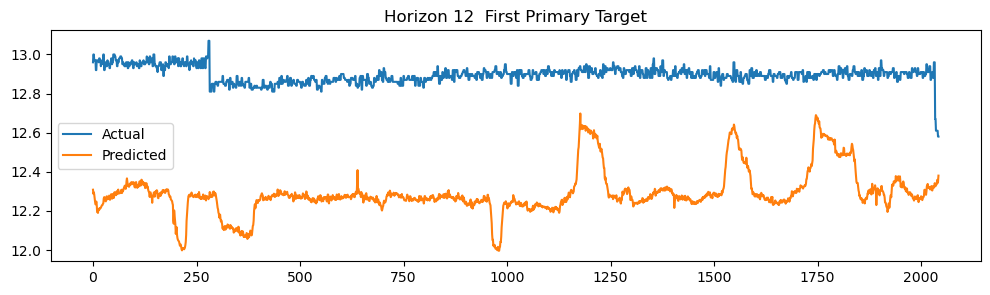

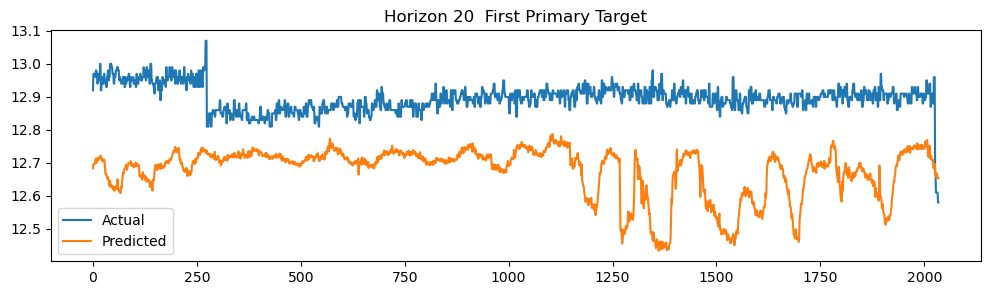

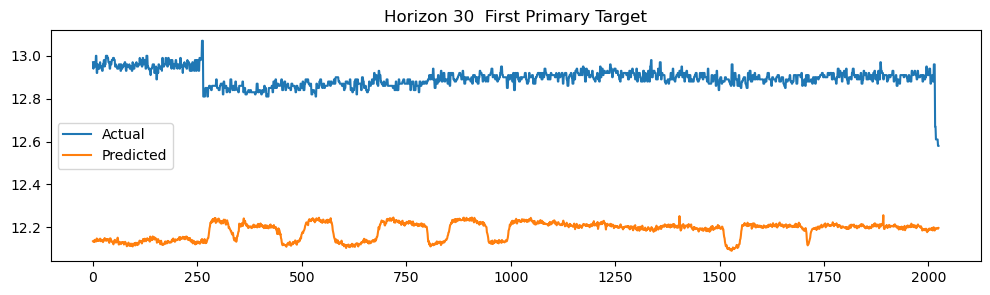

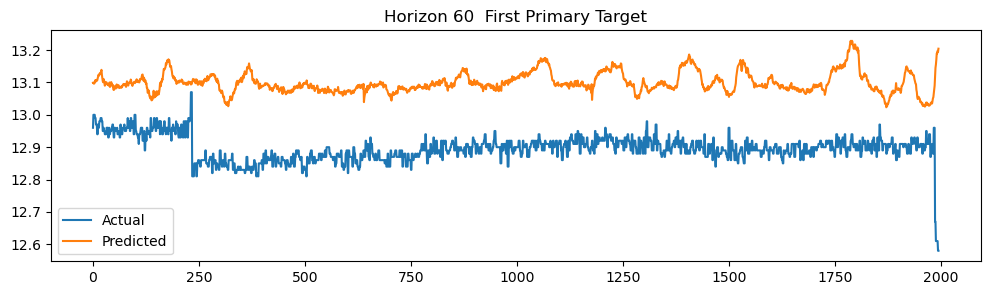

In [29]:
seq_len = 60
batch_size = 64
hidden_size = 128
num_layers = 1
dropout_rate = 0.2
learning_rate = 0.001
num_epochs = 50
patience = 10   # early stopping
if torch.backends.mps.is_available():
    device = torch.device("mps")
horizons = [12, 20, 30, 60]

class LSTMConv(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size,
                 conv_channels=32, kernel_size=3, dropout=0.2):
        super(LSTMConv, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_size,
                               out_channels=conv_channels,
                               kernel_size=kernel_size,
                               padding=kernel_size//2)
        self.relu = nn.ReLU()
        self.lstm = nn.LSTM(conv_channels,
                            hidden_size,
                            num_layers,
                            batch_first=True,
                            dropout=dropout if num_layers>1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
       
        x = x.permute(0,2,1)        
        x = self.conv1(x)
        x = self.relu(x)
        x = x.permute(0,2,1)         
        out, _ = self.lstm(x)
        out = self.dropout(out[:, -1, :])
        out = self.fc(out)
        return out

results = {}
input_size = X_train.shape[1]
output_size = y_train.shape[1]

for h in horizons:
    print(f"\n Training LSTMConv for horizon {h}")
    
    model = LSTMConv(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        output_size=output_size,
        dropout=dropout_rate
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.MSELoss()

    train_loader, val_loader, test_loader = loaders[h]

    best_val_rmse = np.inf
    patience_counter = 0

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(X_batch)
        
        train_loss /= len(train_loader.dataset)


        model.eval()
        val_preds, val_truth = [], []

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                y_hat = model(X_batch)
                val_preds.append(y_hat.cpu().numpy())
                val_truth.append(y_batch.cpu().numpy())

        val_preds = np.vstack(val_preds)
        val_truth = np.vstack(val_truth)

        # rescale
        val_preds_rescaled = scaler_y.inverse_transform(val_preds)
        val_truth_rescaled = scaler_y.inverse_transform(val_truth)

        val_rmse = sqrt(mean_squared_error(val_truth_rescaled.flatten(),val_preds_rescaled.flatten()))

        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            patience_counter = 0
            torch.save(model.state_dict(), f"best_lstmconv_h{h}.pth")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs} Train Loss={train_loss:.6f} Val RMSE={val_rmse:.4f}")

    model.load_state_dict(torch.load(f"best_lstmconv_h{h}.pth"))
    model.eval()


    test_preds, test_truth = [], []
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_hat = model(X_batch)
            test_preds.append(y_hat.cpu().numpy())
            test_truth.append(y_batch.cpu().numpy())

    test_preds = np.vstack(test_preds)
    test_truth = np.vstack(test_truth)

    test_preds_rescaled = scaler_y.inverse_transform(test_preds)
    test_truth_rescaled = scaler_y.inverse_transform(test_truth)

    per_target_rmse_test = [
        sqrt(mean_squared_error(test_truth_rescaled[:, i], test_preds_rescaled[:, i]))
        for i in range(output_size)
    ]

    overall_rmse_test = sqrt(mean_squared_error(
        test_truth_rescaled.flatten(),
        test_preds_rescaled.flatten()
    ))

    print(f"Horizon {h}  Test RMSE: {overall_rmse_test:.4f}")

    results[h] = {
        "model": model,
        "y_val": val_truth_rescaled,
        "y_val_pred": val_preds_rescaled,
        "y_test": test_truth_rescaled,
        "y_test_pred": test_preds_rescaled,
        "overall_rmse_val": best_val_rmse,
        "overall_rmse_test": overall_rmse_test,
        "per_target_rmse_test": per_target_rmse_test
    }


for h in horizons:
    plt.figure(figsize=(12, 3))
    plt.plot(results[h]["y_test"][:, 0], label="Actual")
    plt.plot(results[h]["y_test_pred"][:, 0], label="Predicted")
    plt.title(f"Horizon {h}  First Primary Target")
    plt.legend()
    plt.show()


# Updated the model with a dropout layer and a early stoppping to see if it helps RSME. 


 Training LSTMConv for horizon 12
Epoch 10/50 Train Loss=0.362004, Val Loss=0.894494
Epoch 20/50 Train Loss=0.276844, Val Loss=1.024813
Epoch 30/50 Train Loss=0.258585, Val Loss=1.024958
Epoch 40/50 Train Loss=0.250710, Val Loss=0.950743
Epoch 50/50 Train Loss=0.245809, Val Loss=0.989045

 Training LSTMConv for horizon 20
Epoch 10/50 Train Loss=0.315549, Val Loss=0.699442
Epoch 20/50 Train Loss=0.265341, Val Loss=0.691623
Epoch 30/50 Train Loss=0.256719, Val Loss=0.902992
Epoch 40/50 Train Loss=0.242450, Val Loss=1.048747
Epoch 50/50 Train Loss=0.228093, Val Loss=0.722867

 Training LSTMConv for horizon 30
Epoch 10/50 Train Loss=0.346855, Val Loss=0.892326
Epoch 20/50 Train Loss=0.278671, Val Loss=0.836581
Epoch 30/50 Train Loss=0.257484, Val Loss=0.835014
Epoch 40/50 Train Loss=0.245600, Val Loss=0.733584
Epoch 50/50 Train Loss=0.228135, Val Loss=0.882902

 Training LSTMConv for horizon 60
Epoch 10/50 Train Loss=0.408534, Val Loss=0.817103
Epoch 20/50 Train Loss=0.290262, Val Loss=0.

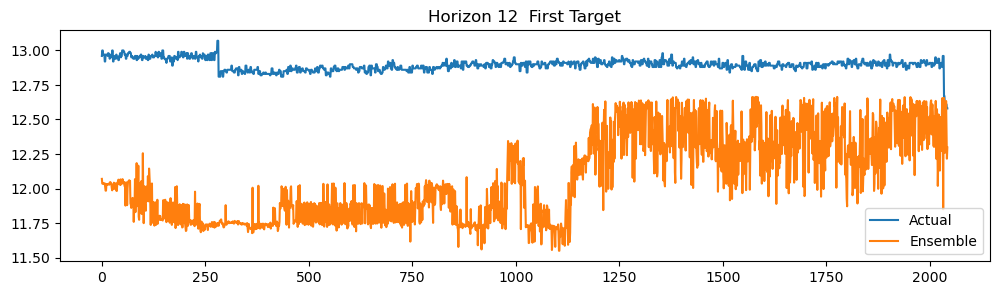

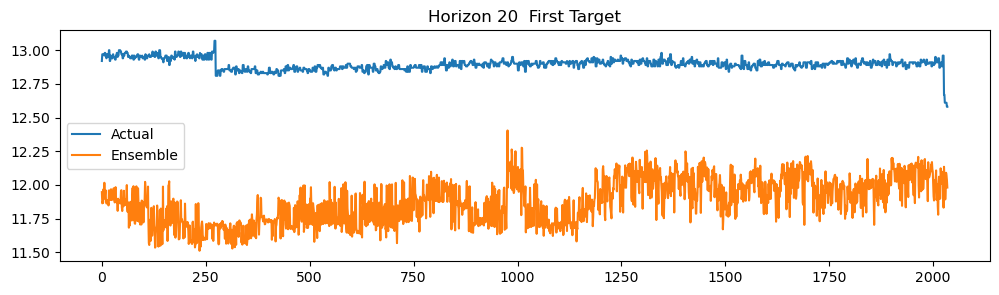

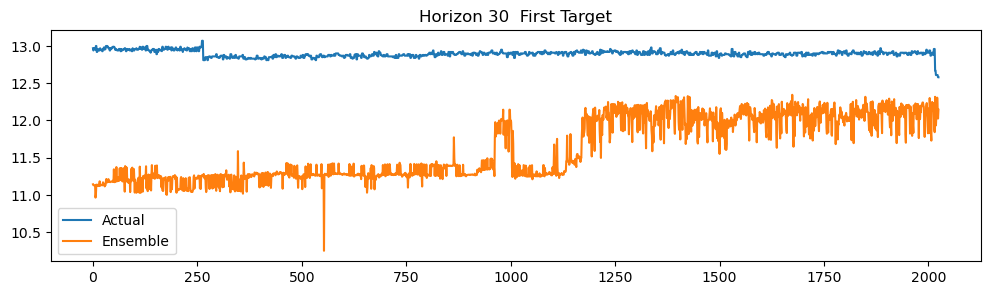

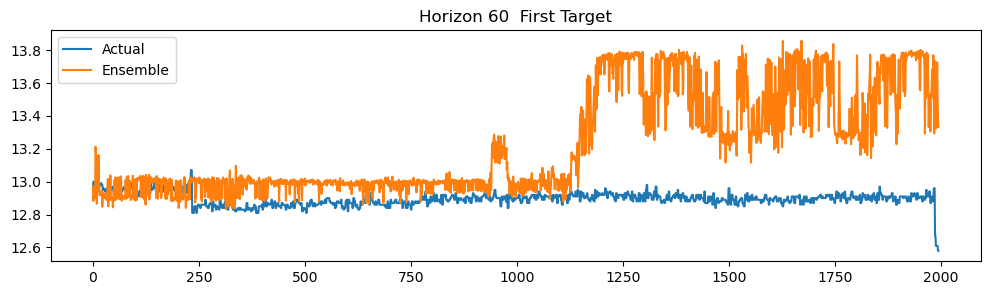

In [30]:
seq_len = 60
batch_size = 64
hidden_size = 128
num_layers = 1
dropout_rate = 0.2
learning_rate = 0.001
num_epochs = 50
alpha = 0.5   
horizons = [12, 20, 30, 60]

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")


results_lstm = {}

input_size = X_train.shape[1]
output_size = y_train.shape[1]

for h in horizons:
    print(f"\n Training LSTMConv for horizon {h}")

    model = LSTMConv(input_size, hidden_size, num_layers, output_size, dropout=dropout_rate).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    criterion = nn.MSELoss()

    train_loader, val_loader, test_loader = loaders[h]

    
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(X_batch)

        epoch_loss /= len(train_loader.dataset)

     
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                y_pred = model(X_batch)
                val_loss += criterion(y_pred, y_batch).item() * len(X_batch)

        val_loss /= len(val_loader.dataset)

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs} Train Loss={epoch_loss:.6f}, Val Loss={val_loss:.6f}")

    def get_predictions(loader):
        preds, actuals = [], []
        model.eval()
        with torch.no_grad():
            for X_batch, y_batch in loader:
                X_batch = X_batch.to(device)
                preds.append(model(X_batch).cpu().numpy())
                actuals.append(y_batch.numpy())
        return np.vstack(preds), np.vstack(actuals)

    val_pred, val_true = get_predictions(val_loader)
    test_pred, test_true = get_predictions(test_loader)

    val_pred_rescaled  = scaler_y.inverse_transform(val_pred)
    val_true_rescaled  = scaler_y.inverse_transform(val_true)

    test_pred_rescaled = scaler_y.inverse_transform(test_pred)
    test_true_rescaled = scaler_y.inverse_transform(test_true)

    results_lstm[h] = {"model": model,
        "val_pred": val_pred_rescaled,
        "val_true": val_true_rescaled,
        "test_pred": test_pred_rescaled,
        "test_true": test_true_rescaled}

    val_rmse = sqrt(mean_squared_error(val_true_rescaled.flatten(), val_pred_rescaled.flatten()))
    test_rmse = sqrt(mean_squared_error(test_true_rescaled.flatten(), test_pred_rescaled.flatten()))


results_lgb = {}

for h in horizons:
    print(f"\nTraining LightGBM for horizon {h}")


    X_train_lgb = np.array([X_train[i:i+seq_len].flatten()
                            for i in range(len(X_train)-seq_len-h+1)])
    y_train_lgb = y_train[seq_len+h-1:]

    X_val_lgb = np.array([X_val[i:i+seq_len].flatten()
                          for i in range(len(X_val)-seq_len-h+1)])
    y_val_lgb = y_val[seq_len+h-1:]

    X_test_lgb = np.array([X_test[i:i+seq_len].flatten()
                           for i in range(len(X_test)-seq_len-h+1)])
    y_test_lgb = y_test[seq_len+h-1:]

    
    lgb_models = []
    for target in range(output_size):
        train_data = lgb.Dataset(X_train_lgb, label=y_train_lgb[:, target])
        params = {"objective": "regression",
            "metric": "rmse",
            "learning_rate": 0.05,
            "num_leaves": 31,
            "verbose": -1}
        m = lgb.train(params, train_data, num_boost_round=200)
        lgb_models.append(m)


    lgb_val  = np.column_stack([m.predict(X_val_lgb)  for m in lgb_models])
    lgb_test = np.column_stack([m.predict(X_test_lgb) for m in lgb_models])

    lgb_val_rescaled  = scaler_y.inverse_transform(lgb_val)
    lgb_test_rescaled = scaler_y.inverse_transform(lgb_test)

    results_lgb[h] = {"val_pred":  lgb_val_rescaled,
        "test_pred": lgb_test_rescaled}

results_ensemble = {}

for h in horizons:
    lstm_val  = results_lstm[h]["val_pred"]
    lgb_val   = results_lgb[h]["val_pred"]

    lstm_test = results_lstm[h]["test_pred"]
    lgb_test  = results_lgb[h]["test_pred"]

    ensemble_val  = alpha * lstm_val  + (1 - alpha) * lgb_val
    ensemble_test = alpha * lstm_test + (1 - alpha) * lgb_test

    val_rmse  = sqrt(mean_squared_error(results_lstm[h]["val_true"].flatten(),  ensemble_val.flatten()))
    test_rmse = sqrt(mean_squared_error(results_lstm[h]["test_true"].flatten(), ensemble_test.flatten()))

    print(f"Horizon {h}  Ensemble Val RMSE = {val_rmse:.4f}, Test RMSE = {test_rmse:.4f}")

    results_ensemble[h] = {"val_pred": ensemble_val,
        "test_pred": ensemble_test}


for h in horizons:
    plt.figure(figsize=(12,3))
    plt.plot(results_lstm[h]["test_true"][:,0], label="Actual")
    plt.plot(results_ensemble[h]["test_pred"][:,0], label="Ensemble")
    plt.title(f"Horizon {h}  First Target")
    plt.legend()
    plt.show()


# removed the early stoppping because the RSME intially increases. Also, combined the LightGBM model with LSTMCOv model for ensemble method with alpha of .5. The method achieves the lowest RSME.

In [31]:
feature_cols = X.columns[1:42].tolist()  
target_cols  = y.columns.tolist()    
print(feature_cols)

print(target_cols)

['AmbientConditions.AmbientTemperature.U.Actual', 'Machine1.RawMaterial.Property1', 'Machine1.RawMaterial.Property2', 'Machine1.RawMaterial.Property3', 'Machine1.RawMaterial.Property4', 'Machine1.RawMaterialFeederParameter.U.Actual', 'Machine1.Zone1Temperature.C.Actual', 'Machine1.Zone2Temperature.C.Actual', 'Machine1.MotorAmperage.U.Actual', 'Machine1.MotorRPM.C.Actual', 'Machine1.MaterialPressure.U.Actual', 'Machine1.MaterialTemperature.U.Actual', 'Machine1.ExitZoneTemperature.C.Actual', 'Machine2.RawMaterial.Property1', 'Machine2.RawMaterial.Property2', 'Machine2.RawMaterial.Property3', 'Machine2.RawMaterial.Property4', 'Machine2.RawMaterialFeederParameter.U.Actual', 'Machine2.Zone1Temperature.C.Actual', 'Machine2.Zone2Temperature.C.Actual', 'Machine2.MotorAmperage.U.Actual', 'Machine2.MotorRPM.C.Actual', 'Machine2.MaterialPressure.U.Actual', 'Machine2.MaterialTemperature.U.Actual', 'Machine2.ExitZoneTemperature.C.Actual', 'Machine3.RawMaterial.Property1', 'Machine3.RawMaterial.Prop


 Training LSTMConv for horizon 12
Epoch 10/50 Train Loss=0.507230, Val Loss=1.646508
Epoch 20/50 Train Loss=0.605007, Val Loss=2.477781
Epoch 30/50 Train Loss=0.296238, Val Loss=5.066658
Epoch 40/50 Train Loss=0.288427, Val Loss=11.930881
Epoch 50/50 Train Loss=0.273951, Val Loss=9.713963

 Training LSTMConv for horizon 20
Epoch 10/50 Train Loss=0.411948, Val Loss=3.508633
Epoch 20/50 Train Loss=0.375689, Val Loss=4.234407
Epoch 30/50 Train Loss=0.298535, Val Loss=3.120621
Epoch 40/50 Train Loss=0.321423, Val Loss=3.196220
Epoch 50/50 Train Loss=0.283626, Val Loss=1.652074

 Training LSTMConv for horizon 30
Epoch 10/50 Train Loss=0.386935, Val Loss=6.368414
Epoch 20/50 Train Loss=0.298494, Val Loss=6.331440
Epoch 30/50 Train Loss=0.269203, Val Loss=5.427515
Epoch 40/50 Train Loss=0.267971, Val Loss=6.490970
Epoch 50/50 Train Loss=0.248758, Val Loss=5.527165

 Training LSTMConv for horizon 60
Epoch 10/50 Train Loss=0.589191, Val Loss=2.932688
Epoch 20/50 Train Loss=0.333605, Val Loss=2

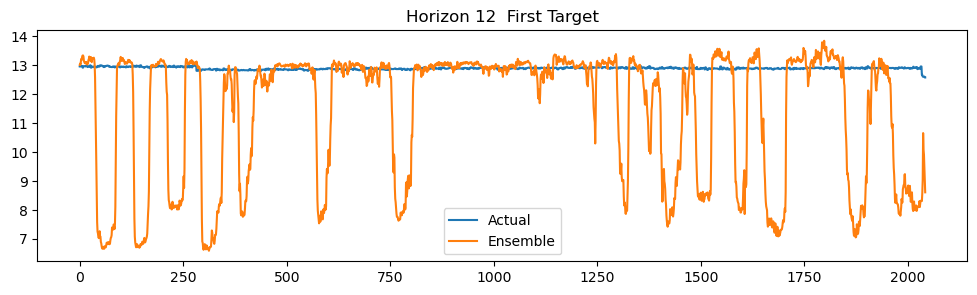

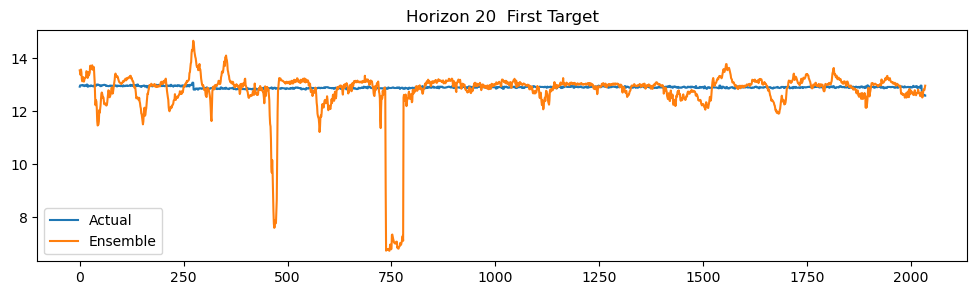

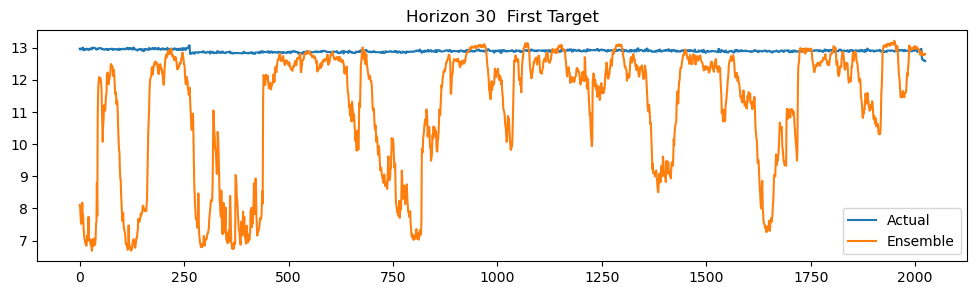

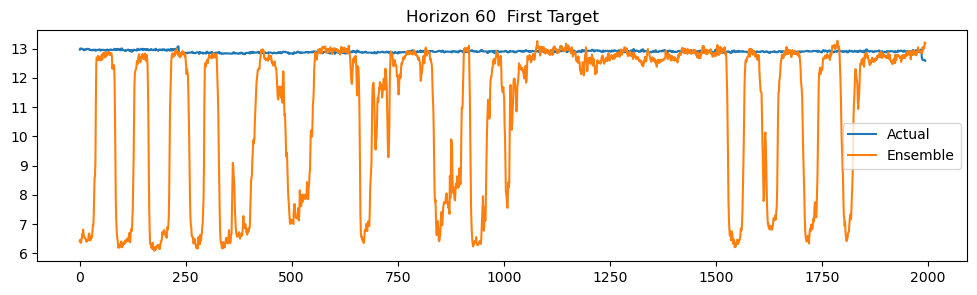

In [32]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_X.fit_transform(df[feature_cols])
y_scaled = scaler_y.fit_transform(df[target_cols])

X_train, X_temp, y_train, y_temp = train_test_split(
    X_scaled, y_scaled, test_size=0.3, shuffle=False
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, shuffle=False
)

datasets = {}
loaders = {}
for h in horizons:
    train_dataset = TimeSeriesDataset(X_train, y_train, seq_len, horizon=h)
    val_dataset   = TimeSeriesDataset(X_val, y_val, seq_len, horizon=h)
    test_dataset  = TimeSeriesDataset(X_test, y_test, seq_len, horizon=h)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


    datasets[h] = (train_dataset, val_dataset, test_dataset)
    loaders[h] = (train_loader, val_loader, test_loader)

seq_len = 60
batch_size = 64
hidden_size = 128
num_layers = 1
dropout_rate = 0.2
learning_rate = 0.001
num_epochs = 50
alpha = 0.5   
horizons = [12, 20, 30, 60]

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")


results_lstm = {}

input_size = X_train.shape[1]
output_size = y_train.shape[1]

for h in horizons:
    print(f"\n Training LSTMConv for horizon {h}")

    model = LSTMConv(input_size, hidden_size, num_layers, output_size, dropout=dropout_rate).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    criterion = nn.MSELoss()

    train_loader, val_loader, test_loader = loaders[h]

    
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(X_batch)

        epoch_loss /= len(train_loader.dataset)

     
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                y_pred = model(X_batch)
                val_loss += criterion(y_pred, y_batch).item() * len(X_batch)

        val_loss /= len(val_loader.dataset)

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs} Train Loss={epoch_loss:.6f}, Val Loss={val_loss:.6f}")

    def get_predictions(loader):
        preds, actuals = [], []
        model.eval()
        with torch.no_grad():
            for X_batch, y_batch in loader:
                X_batch = X_batch.to(device)
                preds.append(model(X_batch).cpu().numpy())
                actuals.append(y_batch.numpy())
        return np.vstack(preds), np.vstack(actuals)

    val_pred, val_true = get_predictions(val_loader)
    test_pred, test_true = get_predictions(test_loader)

    val_pred_rescaled  = scaler_y.inverse_transform(val_pred)
    val_true_rescaled  = scaler_y.inverse_transform(val_true)

    test_pred_rescaled = scaler_y.inverse_transform(test_pred)
    test_true_rescaled = scaler_y.inverse_transform(test_true)

    results_lstm[h] = {"model": model,
        "val_pred": val_pred_rescaled,
        "val_true": val_true_rescaled,
        "test_pred": test_pred_rescaled,
        "test_true": test_true_rescaled}

    val_rmse = sqrt(mean_squared_error(val_true_rescaled.flatten(), val_pred_rescaled.flatten()))
    test_rmse = sqrt(mean_squared_error(test_true_rescaled.flatten(), test_pred_rescaled.flatten()))


results_lgb = {}

for h in horizons:
    print(f"\nTraining LightGBM for horizon {h}")


    X_train_lgb = np.array([X_train[i:i+seq_len].flatten()
                            for i in range(len(X_train)-seq_len-h+1)])
    y_train_lgb = y_train[seq_len+h-1:]

    X_val_lgb = np.array([X_val[i:i+seq_len].flatten()
                          for i in range(len(X_val)-seq_len-h+1)])
    y_val_lgb = y_val[seq_len+h-1:]

    X_test_lgb = np.array([X_test[i:i+seq_len].flatten()
                           for i in range(len(X_test)-seq_len-h+1)])
    y_test_lgb = y_test[seq_len+h-1:]

    
    lgb_models = []
    for target in range(output_size):
        train_data = lgb.Dataset(X_train_lgb, label=y_train_lgb[:, target])
        params = {"objective": "regression",
            "metric": "rmse",
            "learning_rate": 0.05,
            "num_leaves": 31,
            "verbose": -1}
        m = lgb.train(params, train_data, num_boost_round=200)
        lgb_models.append(m)


    lgb_val  = np.column_stack([m.predict(X_val_lgb)  for m in lgb_models])
    lgb_test = np.column_stack([m.predict(X_test_lgb) for m in lgb_models])

    lgb_val_rescaled  = scaler_y.inverse_transform(lgb_val)
    lgb_test_rescaled = scaler_y.inverse_transform(lgb_test)

    results_lgb[h] = {"val_pred":  lgb_val_rescaled,
        "test_pred": lgb_test_rescaled}

results_ensemble = {}

for h in horizons:
    lstm_val  = results_lstm[h]["val_pred"]
    lgb_val   = results_lgb[h]["val_pred"]

    lstm_test = results_lstm[h]["test_pred"]
    lgb_test  = results_lgb[h]["test_pred"]

    ensemble_val  = alpha * lstm_val  + (1 - alpha) * lgb_val
    ensemble_test = alpha * lstm_test + (1 - alpha) * lgb_test

    val_rmse  = sqrt(mean_squared_error(results_lstm[h]["val_true"].flatten(),  ensemble_val.flatten()))
    test_rmse = sqrt(mean_squared_error(results_lstm[h]["test_true"].flatten(), ensemble_test.flatten()))

    print(f"Horizon {h}  Ensemble Val RMSE = {val_rmse:.4f}, Test RMSE = {test_rmse:.4f}")

    results_ensemble[h] = {"val_pred": ensemble_val,
        "test_pred": ensemble_test}


for h in horizons:
    plt.figure(figsize=(12,3))
    plt.plot(results_lstm[h]["test_true"][:,0], label="Actual")
    plt.plot(results_ensemble[h]["test_pred"][:,0], label="Ensemble")
    plt.title(f"Horizon {h}  First Target")
    plt.legend()
    plt.show()

# For sanity check, tested the ensemble method without PCA. RMSE is higher and the graph looks off. The graph keeps dropping below. Trained pca on just train dataset so there are no leaks for test dataset from pca. 